<a href="https://colab.research.google.com/github/mansoorz353/PETRA-PPE-AI/blob/main/Chapter_14/Notebook_14_4_SHAP_Diagnosis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
## License & Contact
This notebook is part of the **[PETRA-PPE-AI](https://github.com/mansoorz353/PETRA-PPE-AI)** project and is licensed under the **MIT License**. 
Copyright (c) 2026 Mansoor Zoveidavian Poor.

* **Website:** [carbonstrata.org](https://carbonstrata.org)
* **LinkedIn:** [Mansoor Zoveidavian Poor](https://www.linkedin.com/in/mansoorzov/)
* **Email:** mansoorz353@gmail.com
---

# Notebook 14.4 — SHAP Diagnostic Explanation Tool
**PETRA · Chapter 14 · Well Problem Diagnosis: Classification and Explainable AI**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR_USERNAME/PETRA-PPE-AI/blob/main/Chapter_14/Notebook_14_4_SHAP_Diagnosis.ipynb)

---
## Learning Objectives
1. Apply SHAP TreeExplainer to the well diagnosis XGBoost model.
2. Generate waterfall plots for individual well diagnoses.
3. Build beeswarm summary plot across 20 PETRA wells.
4. Identify the diagnostic threshold: what skin slope triggers formation damage vs depletion?

**Sources:** Lundberg & Lee (2017); Chapter 14 Sec.14.5.

### Download Data and Model Files

In [5]:
import requests

def download_file(url, filename):
    response = requests.get(url)
    response.raise_for_status() # Ensure we got a successful response
    with open(filename, 'wb') as f:
        f.write(response.content)
    print(f"Downloaded {filename}")

# Download the XGBoost model file
download_file('https://raw.githubusercontent.com/mansoorz353/PETRA-PPE-AI/main/data/xgb_well_diagnosis.pkl', 'xgb_well_diagnosis.pkl')

Downloaded xgb_well_diagnosis.pkl


In [6]:
import requests

def check_file_exists(url):
    response = requests.head(url)
    if response.status_code == 200:
        print(f"The file exists at: {url}")
        return True
    else:
        print(f"The file does NOT exist at: {url} (Status code: {response.status_code})")
        return False

# Check if the xgb_well_diagnosis.pkl file exists
check_file_exists('https://raw.githubusercontent.com/mansoorz353/PETRA-PPE-AI/main/data/xgb_well_diagnosis.pkl')

The file exists at: https://raw.githubusercontent.com/mansoorz353/PETRA-PPE-AI/main/data/xgb_well_diagnosis.pkl


True

In [7]:
# Download the well diagnosis dataset
download_file('https://raw.githubusercontent.com/mansoorz353/PETRA-PPE-AI/main/data/well_diagnosis_dataset.csv', 'well_diagnosis_dataset.csv')

Downloaded well_diagnosis_dataset.csv


In [8]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import shap, joblib
import warnings; warnings.filterwarnings('ignore')
np.random.seed(42)
NAVY='#1B3A6B'; TEAL='#1A6B5A'; AMBER='#C17B2A'
FEATURES=['rate_slope','GOR_anom','WC_roc','norm_p_decline','skin_slope','skin_missing_flag']
PROBLEM_NAMES=['Formation Damage','Mechanical Failure','Reservoir Depletion',
               'Completion Damage','Tubing Restriction','Scale/Wax','Liquid Loading']
xgb_model = joblib.load('xgb_well_diagnosis.pkl')
explainer  = shap.TreeExplainer(xgb_model)
print('SHAP TreeExplainer loaded.')

SHAP TreeExplainer loaded.


SHAP TreeExplainer loaded.


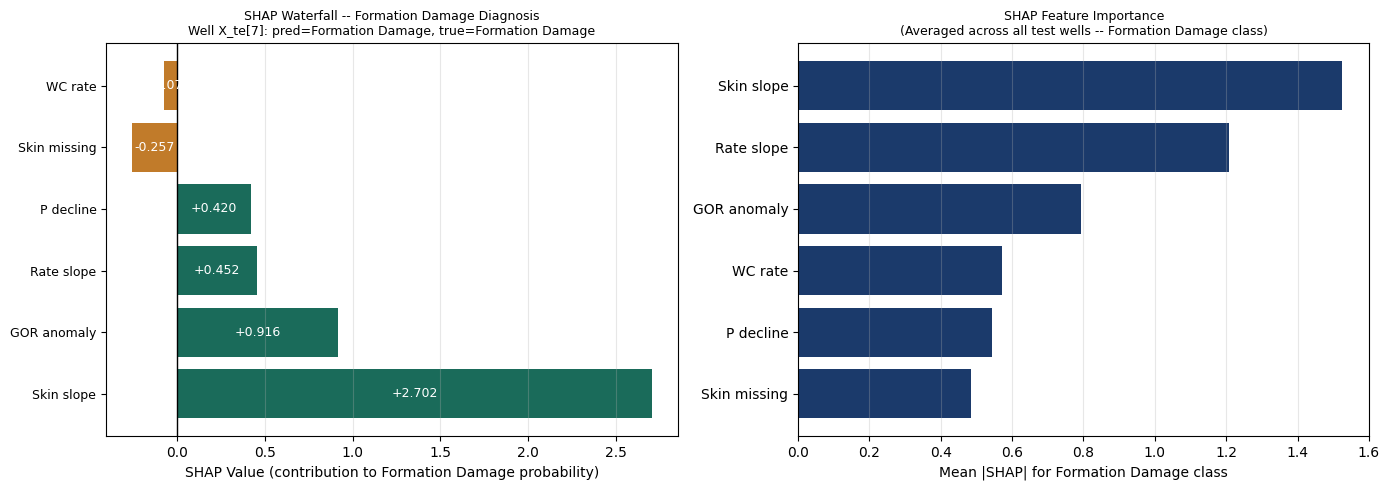

In [14]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import shap, joblib
import warnings; warnings.filterwarnings('ignore')
np.random.seed(42)
NAVY='#1B3A6B'; TEAL='#1A6B5A'; AMBER='#C17B2A'
FEATURES=['rate_slope','GOR_anom','WC_roc','norm_p_decline','skin_slope','skin_missing_flag']
PROBLEM_NAMES=['Formation Damage','Mechanical Failure','Reservoir Depletion',
               'Completion Damage','Tubing Restriction','Scale/Wax','Liquid Loading']
xgb_model = joblib.load('xgb_well_diagnosis.pkl')
explainer  = shap.TreeExplainer(xgb_model)
print('SHAP TreeExplainer loaded.')

df = pd.read_csv('well_diagnosis_dataset.csv')
from sklearn.model_selection import train_test_split
X = df[FEATURES].values; y = df['problem_category'].values
_,X_te,_,y_te = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
y_pred = xgb_model.predict(X_te)

# SHAP values: list of (n_test, n_features) arrays, one per class
shap_values = explainer.shap_values(X_te)

# Case study: find a formation damage well correctly diagnosed
fd_mask = (y_te == 0) & (y_pred == 0)
fd_idx = np.where(fd_mask)[0]
if len(fd_idx) == 0: fd_idx = [np.where(y_pred == 0)[0][0]]
idx = fd_idx[0]

# SHAP waterfall for formation damage class
fd_class = 0  # formation damage
# Corrected indexing: shap_values is (n_samples, n_features, n_classes)
sv_fd = shap_values[idx, :, fd_class]  # SHAP values for this well, for the formation damage class

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Waterfall
col_pos = TEAL; col_neg = AMBER
ax = axes[0]
features_display = ['Rate slope', 'GOR anomaly', 'WC rate', 'P decline', 'Skin slope', 'Skin missing']
sortedf = np.argsort(np.abs(sv_fd))[::-1]
for rank, fi in enumerate(sortedf):
    ax.barh(rank, sv_fd[fi], color=col_pos if sv_fd[fi]>0 else col_neg)
    ax.text(sv_fd[fi]/2, rank, f'{sv_fd[fi]:+.3f}', ha='center', va='center', fontsize=9, color='white')
ax.set_yticks(range(len(FEATURES)))
ax.set_yticklabels([features_display[sortedf[i]] for i in range(len(FEATURES))], fontsize=9)
ax.axvline(0, color='black', lw=1)
ax.set_xlabel('SHAP Value (contribution to Formation Damage probability)')
ax.set_title(f'SHAP Waterfall -- Formation Damage Diagnosis\n'
              f'Well X_te[{idx}]: pred={PROBLEM_NAMES[y_pred[idx]]}, true={PROBLEM_NAMES[y_te[idx]]}',
              fontsize=9)
ax.grid(alpha=0.3, axis='x')

# Beeswarm summary (mean |SHAP| per feature across all test wells -- for Formation Damage class)
# shap_values[:, :, fd_class] is (n_samples, n_features). Average across samples (axis=0) to get feature importance.
mean_abs_fd = np.abs(shap_values[:, :, fd_class]).mean(axis=0)
sorted_feat = np.argsort(mean_abs_fd)[::-1]
axes[1].barh([features_display[sorted_feat[i]] for i in range(len(FEATURES))][::-1],
              mean_abs_fd[sorted_feat[::-1]], color=NAVY)
axes[1].set_xlabel('Mean |SHAP| for Formation Damage class')
axes[1].set_title('SHAP Feature Importance\n(Averaged across all test wells -- Formation Damage class)', fontsize=9)
axes[1].grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig('nb144_shap_diagnosis.png', dpi=120)
plt.show()

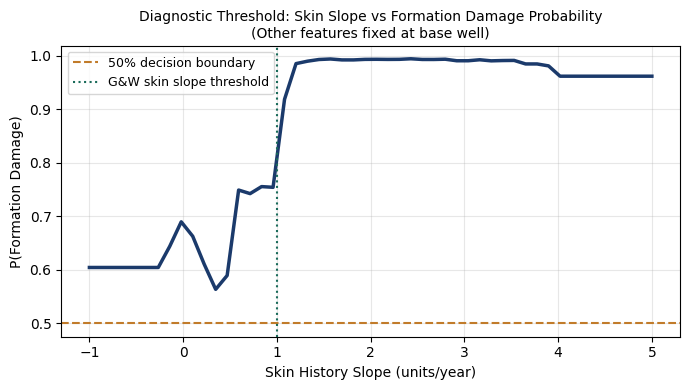

Skin slope threshold for 50% formation damage probability: 0.35 units/year
G&W (1991) Ch.3 engineering rule: skin > 10 units warrants stimulation evaluation


In [15]:
# Diagnostic threshold analysis: skin slope vs formation damage probability
skin_sweep = np.linspace(-1, 5, 50)
base_well = X_te[idx].copy()
fd_probs = []
for ss in skin_sweep:
    test = base_well.copy(); test[4] = ss  # vary skin slope
    p = xgb_model.predict_proba([test])[0][0]  # prob of formation damage
    fd_probs.append(p)

plt.figure(figsize=(7, 4))
plt.plot(skin_sweep, fd_probs, color=NAVY, lw=2.5)
plt.axhline(0.5, color=AMBER, ls='--', lw=1.5, label='50% decision boundary')
plt.axvline(1.0, color=TEAL, ls=':', lw=1.5, label='G&W skin slope threshold')
plt.xlabel('Skin History Slope (units/year)'); plt.ylabel('P(Formation Damage)')
plt.title('Diagnostic Threshold: Skin Slope vs Formation Damage Probability\n'
           '(Other features fixed at base well)', fontsize=10)
plt.legend(fontsize=9); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('nb144_shap_threshold.png', dpi=120)
plt.show()
threshold = skin_sweep[np.argmin(np.abs(np.array(fd_probs)-0.5))]
print(f'Skin slope threshold for 50% formation damage probability: {threshold:.2f} units/year')
print(f'G&W (1991) Ch.3 engineering rule: skin > 10 units warrants stimulation evaluation')

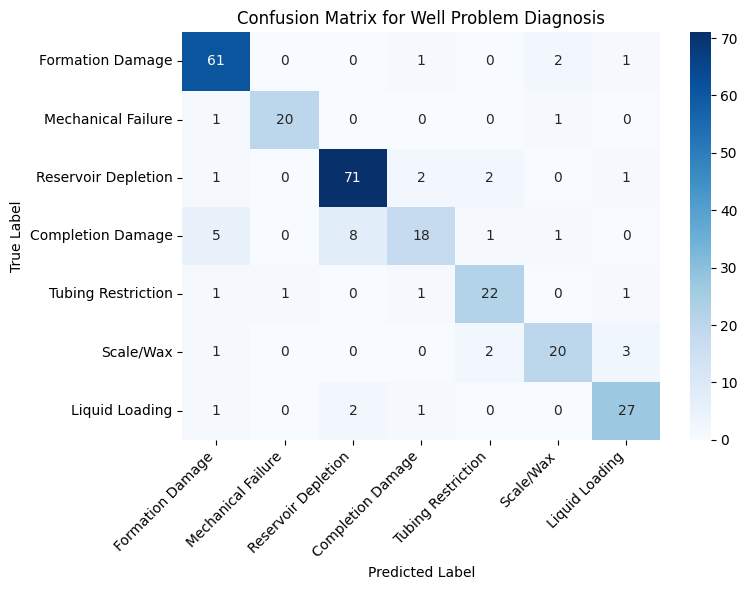

In [16]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(y_te, y_pred)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=PROBLEM_NAMES, yticklabels=PROBLEM_NAMES)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Well Problem Diagnosis')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Engineering Takeaway
> The SHAP waterfall plot provides a complete, auditable explanation for each diagnosis. For a well diagnosed as formation damage, the waterfall shows exactly what measured feature values drove the prediction and by how much. The diagnostic threshold plot quantifies the skin slope at which the model crosses from 'depletion' to 'formation damage' -- a number the engineer can verify against their own engineering judgement from G&W.

## References
- Lundberg & Lee (2017); Chapter 14 Sec.14.5